```{contents}
:local:
:depth: 2
```

# 5.2 Robust Optimization

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 13, Lesson 4: *Robust Optimization*
- Module 13, Lesson 5: *Robust Optimization Example*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Describe uncertainty with a set (box, ellipsoid or polyhedron) and explain what it means for a solution to be robust feasible.
- Derive the robust counterpart of a linear constraint under box uncertainty and see why it has finitely many constraints.
- Solve the robust farmer's problem, measure the price of robustness, and explain how adjustable decisions recover some of it.
- Compare robust and stochastic solutions, and recognize measurement noise in a black box as a form of uncertainty these frameworks address.
:::

In {doc}`Topic5.1-Stochastic_Programming` stochastic programming was used to optimize the average outcome, which requires that the probability of each scenario is known. However, in many cases the probabilities are not known, and only the range of a parameter can be specified. In other cases the average is not really the right target, since a plan that violates a safety limit or a supply contract in one scenario out of three is not acceptable even if it does well on average. **Robust optimization** (RO) is designed for these cases: the goal is to find a solution that stays feasible for *every* value of the uncertain parameters in a given set, and to optimize the worst case. RO is therefore useful wherever feasibility or reliability is critical, and the lectures give power systems, portfolio management and water-resource management as examples.

## Uncertainty sets and robust counterparts

In robust optimization each uncertain parameter is written as a nominal value plus a perturbation, $a = \bar a + \hat a\, \xi$. Here $\bar a$ is the nominal value and $\hat a$ is the largest deviation, while the scaled perturbation $\xi$ is not known exactly and is only assumed to lie in an **uncertainty set** $\mathcal{U}$. The three most common shapes are:

- a **box**, $\|\xi\|_\infty \le 1$: each parameter varies independently within its range;
- an **ellipsoid**, $\|\xi\|_2 \le \Omega$: large deviations in all parameters at once are excluded;
- a **polyhedron**, for example the budget set $\|\xi\|_\infty \le 1,\ \|\xi\|_1 \le \Gamma$ of Bertsimas and Sim, in which at most about $\Gamma$ parameters reach their extremes at the same time.

We say that a solution is **robust feasible** if it satisfies the constraints for every $\xi \in \mathcal{U}$. If we consider a single linear constraint $a^\top x \le b$, the requirement becomes one constraint for each of the infinitely many points in the set, which is called a **semi-infinite** program and cannot be handed to a solver directly. The trick is to realize that requiring the constraint to hold "for all $\xi$" is the same as requiring it to hold "for the worst $\xi$", so we can write:

$$
\bar a^\top x + \max_{\xi \in \mathcal{U}} \sum_j \hat a_j x_j \xi_j \le b.
$$

For a box, the inner maximum is found by setting each $\xi_j = \pm 1$ so that it matches the sign of $x_j$, which means that the constraint becomes $\bar a^\top x + \sum_j \hat a_j |x_j| \le b$. This is not linear, but it can be made linear again by introducing an auxiliary variable $t_j \ge \pm x_j$. If $x \ge 0$, which is the case in most process models, it simplifies even further to $(\bar a + \hat a)^\top x \le b$, i.e. every coefficient is set to the worst value. This finite, deterministic replacement for the original constraint is called the **robust counterpart**. For an ellipsoid the inner maximum is $\Omega \|\mathrm{diag}(\hat a) x\|_2$, so the counterpart is a second-order cone constraint. For the budget set we can apply LP duality to the inner maximum (the tool we used in {doc}`../2-nonlinear_mixed_integer/Topic2.3-Duality`), which turns it into a handful of extra linear constraints. In each case the robust counterpart ends up being about the same size as the original problem. This is a practical advantage over stochastic programming, since the deterministic equivalent of a stochastic program grows with the number of scenarios.

:::{exercise}
:label: ex-t52-counterpart

Write the robust counterpart of $3x_1 + 2x_2 \le 12$ with $x_1, x_2 \ge 0$ when each coefficient may deviate by up to 10% of its nominal value, for (a) a box and (b) the budget set with $\Gamma = 1$. For $\Gamma = 1$, argue directly (without duality) which coefficient the adversary should perturb for a given $x$.
:::

## The robust farmer

:::{admonition} Adapted from the course notebook
:class: note
Adapted from `farmer_problem.ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT), section "Robust optimization formulation", which follows the farmer's problem of Birge and Louveaux. Rewritten as one Pyomo model that serves the nominal, robust and scenario-evaluation cases, solved with HiGHS.
:::

In the lectures the farmer's problem is changed in one way that makes feasibility matter: **feed cannot be bought**, so the 200 t of wheat and 240 t of corn needed by the cattle have to be grown on the farm. Otherwise the data are the same as in Topic 5.1, and the yields are assumed to be uncertain within 20% of their means. Since purchases are no longer possible, the only recourse that is available after the harvest is the choice of how much of each crop is sold.

The feed constraint for corn is $y_\text{corn}\, x_\text{corn} - s_\text{corn} \ge 240$, where $s$ is the amount that is sold. Since the uncertain yield multiplies an acreage that is nonnegative, the argument above shows that the robust counterpart under a 20% box simply replaces $y$ by $0.8\,\bar y$. The same is true for wheat and for the beets that are available to sell, which means that the robust model is just the nominal model with the yields reduced by the uncertainty fraction $\theta$, and is therefore the same size as the original model. A single Pyomo model can be used for the nominal, robust and scenario cases:

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
import pyomo.environ as pyo
from _lib.part4b_tools import solve_linear

CROPS, FEED = ['wheat', 'corn', 'beets'], ['wheat', 'corn']
YIELD = {'wheat': 2.5, 'corn': 3.0, 'beets': 20.0}         # t/acre, nominal
PLANT = {'wheat': 150, 'corn': 230, 'beets': 260}         # $/acre
SELL = {'wheat': 170, 'corn': 150}                        # $/t
NEED = {'wheat': 200, 'corn': 240}                        # t, must be grown
LAND, QUOTA = 500, 6000

def farm(scenarios, acres=None):
    """No feed purchases. scenarios: {name: (probability, yield factor)}. Returns (profit, acres),
    or (None, None) if no sales plan can meet the feed requirement."""
    S = list(scenarios)
    m = pyo.ConcreteModel()
    m.x = pyo.Var(CROPS, within=pyo.NonNegativeReals)
    m.sell = pyo.Var(FEED, S, within=pyo.NonNegativeReals)
    m.beet_hi = pyo.Var(S, bounds=(0, QUOTA))
    m.beet_lo = pyo.Var(S, within=pyo.NonNegativeReals)
    m.land = pyo.Constraint(expr=sum(m.x[c] for c in CROPS) <= LAND)
    m.feed = pyo.Constraint(FEED, S, rule=lambda m, c, s:
                            scenarios[s][1] * YIELD[c] * m.x[c] - m.sell[c, s] >= NEED[c])
    m.beets = pyo.Constraint(S, rule=lambda m, s:
                             m.beet_hi[s] + m.beet_lo[s] <= scenarios[s][1] * YIELD['beets'] * m.x['beets'])
    if acres is not None:
        for c in CROPS:
            m.x[c].fix(acres[c])
    m.profit = pyo.Objective(sense=pyo.maximize, expr=sum(scenarios[s][0] * (
        sum(SELL[c] * m.sell[c, s] for c in FEED) + 36 * m.beet_hi[s] + 10 * m.beet_lo[s]) for s in S)
        - sum(PLANT[c] * m.x[c] for c in CROPS))
    try:
        return solve_linear(m), {c: pyo.value(m.x[c]) for c in CROPS}
    except Exception:                       # infeasible: the feed requirement cannot be met
        return None, None

SCEN = {'20% low': (1 / 3, 0.8), 'at the mean': (1 / 3, 1.0), '20% high': (1 / 3, 1.2)}

def report(name, acres, promised):
    outcomes = {s: farm({s: (1.0, f)}, acres=acres)[0] for s, (p, f) in SCEN.items()}
    cells = ''.join(f"{'infeasible' if z is None else f'${z:,.0f}':>13s}" for z in outcomes.values())
    print(f"{name:14s}{round(acres['wheat']):>6d}{round(acres['corn']):>6d}{round(acres['beets']):>6d}"
          f"{f'${promised:,.0f}':>11s}{cells}")
    return outcomes

print(f"{'plan':14s}{'wheat':>6s}{'corn':>6s}{'beets':>6s}{'promised':>11s}" + ''.join(f"{s:>13s}" for s in SCEN))
z_nom, x_nom = farm({'nominal': (1.0, 1.0)})
out_nom = report('nominal', x_nom, z_nom)
z_rob, x_rob = farm({'worst case': (1.0, 0.8)})
out_rob = report('robust', x_rob, z_rob)

plan           wheat  corn beets   promised      20% low  at the mean     20% high


nominal          120    80   300   $118,600   infeasible     $118,600     $148,000


robust           100   100   300    $56,800      $56,800     $117,500     $147,000


The nominal plan is the same as the deterministic plan from Topic 5.1, with 120, 80 and 300 acres and a promised profit of \$118,600. Since the farmer can no longer buy feed, this plan is **infeasible** in a bad year, because 80 acres of corn at 80% yield only make 192 t, which is short of the 240 t needed by the cattle. This is the second effect of uncertainty that the lectures emphasize. In Topic 5.1 we saw that a deterministic plan can be *inferior* on average, and here we see that it can also be *infeasible*.

The robust plan plants 100 acres each of wheat and corn and 300 acres of beets. At 80% yields this gives exactly 200 t of wheat and 240 t of corn, so the feed constraints are active in the worst case and are satisfied in every other case. The objective of \$56,800 is a guarantee, since it is the worst-case profit, which is 52% below the nominal promise. However, this number is computed as if the sales were also decided at the worst-case yields. In reality the crops are sold after the harvest, so more is sold if the year is average or good. If we re-optimize the sales for the realized yields, the robust plan earns \$117,500 in a mean year and \$147,000 in a good one.

:::{exercise}
:label: ex-t52-box

The box treats the three yields as independent, but the robust counterpart above used the same 80% for all three. Show that for this model the two give the same answer, by arguing which yield each constraint depends on. Then change the uncertainty to "corn may be 30% low, wheat and beets only 10% low" and re-solve. How much of the price of robustness comes from corn?
:::

## The price of robustness and adjustable decisions

The size of the uncertainty set is a modeling choice that sets a trade-off, since a larger set protects against more but guarantees less. In order to see this trade-off the fraction $\theta$ is swept from 0 to 0.3, and for each robust plan the guaranteed profit is recorded along with whether the plan survives the 20%-low year and what its expected profit is over the three scenarios of Topic 5.1 when the sales are adjusted to the harvest.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


theta = 0.00: guaranteed $  118,600   expected infeasible in a 20%-low year
theta = 0.05: guaranteed $  105,901   expected infeasible in a 20%-low year
theta = 0.10: guaranteed $   91,244   expected infeasible in a 20%-low year
theta = 0.15: guaranteed $   73,976   expected infeasible in a 20%-low year
theta = 0.20: guaranteed $   56,800   expected $107,100
theta = 0.25: guaranteed $   39,733   expected $107,040
theta = 0.30: guaranteed $   22,800   expected $106,971


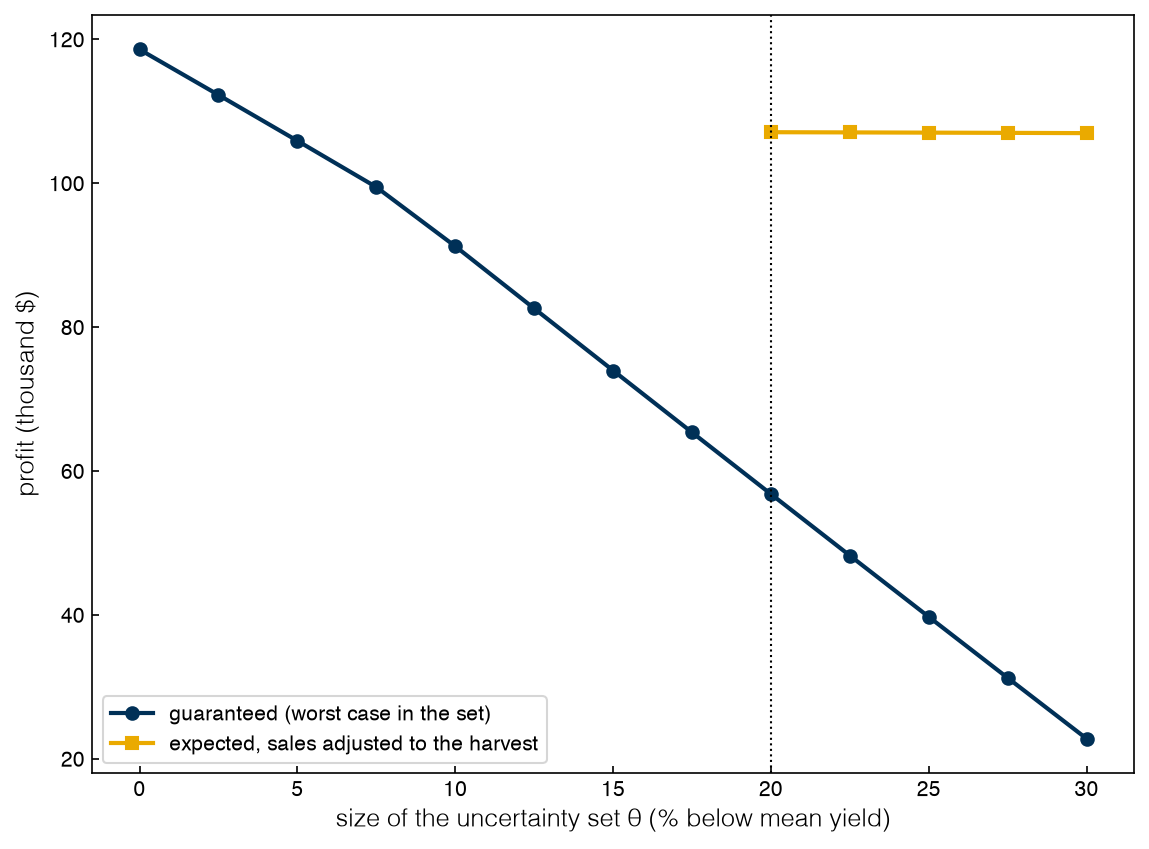

In [2]:
thetas = np.arange(0.0, 0.301, 0.025)
guaranteed, expected = [], []
for th in thetas:
    z, x = farm({'worst case': (1.0, 1 - th)})
    out = [farm({s: (1.0, f)}, acres=x)[0] for s, (p, f) in SCEN.items()]
    guaranteed.append(z)
    expected.append(np.nan if None in out else np.mean(out))
for th, g, e in zip(thetas, guaranteed, expected):
    if abs(th * 40 - round(th * 40)) < 1e-9 and round(th * 40) % 2 == 0:     # print every 0.05
        print(f"theta = {th:.2f}: guaranteed ${g:>9,.0f}   expected "
              + ("infeasible in a 20%-low year" if np.isnan(e) else f"${e:,.0f}"))

fig, ax = plt.subplots()
ax.plot(thetas * 100, np.array(guaranteed) / 1e3, 'o-', label='guaranteed (worst case in the set)')
ax.plot(thetas * 100, np.array(expected) / 1e3, 's-', label='expected, sales adjusted to the harvest')
ax.axvline(20, color='k', ls=':', lw=1)
ax.set_xlabel(r'size of the uncertainty set $\theta$ (% below mean yield)')
ax.set_ylabel('profit (thousand $)')
ax.legend(fontsize=10);

The guaranteed profit shows a steep and almost linear decrease with $\theta$, from \$118,600 at $\theta = 0$ to \$22,800 at $\theta = 0.3$. Every plan with $\theta < 0.2$ is infeasible in the 20%-low year, because it protects against less than what actually happens. From $\theta = 0.2$ on the plans survive, with an expected profit (with adjusted sales) that is nearly flat at about \$107,000. The decrease in expected profit is far slower than the decrease in the guarantee, since the guarantee assumes the worst case happens *and* that nothing can be adjusted once the yields are known.

This second assumption is the main source of conservatism, and **adjustable robust optimization** (ARO) is introduced in the lectures as a way of removing it. In ARO the decisions that are taken after the uncertainty is revealed are allowed to depend on it through a **decision rule**, for example an affine rule $s(\xi) = s_0 + S\xi$, where the coefficients $s_0$ and $S$ become the decision variables. This is the same idea as the second-stage variables of stochastic programming, with an uncertainty set used in place of the scenarios. The difficulty is that the form of the decision rule has to be chosen in advance; anything richer than an affine rule makes the robust counterpart hard to write. In the farmer's problem adjusting the sales is easy because each sale depends only on the yield of the corresponding crop, and so the re-optimized sales above are equivalent to the result of an adjustable rule.

:::{exercise}
:label: ex-t52-aro

Solve the no-purchase farmer as a stochastic program over the three scenarios of Topic 5.1, `farm(SCEN)`, in which the sales already adapt to each scenario. Is its plan feasible in a 20%-low year? Compare its expected profit and its worst-case profit with the robust plan's. Why is this plan robust feasible for the whole 20% box, not just for the three scenarios?
:::

## Robust versus stochastic

The two frameworks answer different questions, as summarized in the table below, and the farmer's problem shows both answers.

| | Stochastic programming | Robust optimization |
|---|---|---|
| What we must know | probabilities of scenarios (or a distribution to sample) | only a set of possible values |
| Objective | expected value | worst case over the set |
| Feasibility | in every scenario modeled | for every point in the set |
| Size | grows with the number of scenarios | about the size of the nominal model |
| Character of the solution | does well on average; can be optimistic | protected; can be too conservative |
| Fits | repeated decisions, long-run averages | safety limits, contracts, one-shot decisions |

In the lectures the difference is summarized by the number of scenarios considered by each framework. Stochastic programming considers many scenarios weighted by probability, whereas static robust optimization effectively considers only one, which is the worst case, and adjustable robust optimization sits between these two extremes. In practice the choice is driven by what is known about the uncertainty and by the cost of a violation. If a shortfall can be bought out at a known price, as was the case in Topic 5.1, the stochastic program is able to price it; if it cannot, as is the case here, feasibility has to come first.

:::{exercise}
:label: ex-t52-compare

Return to the purchasing version of Topic 5.1 and add the robust requirement that the farm grow at least 80% of the cattle's feed itself in a 20%-low year, so that purchases are limited. Solve the stochastic program with this extra constraint. What does the partial robustness cost in expected profit? (This is a simple example of mixing the two frameworks.)
:::

## Noisy black boxes

The last lecture of Module 13 brings uncertainty back to data-driven optimization, following the work of Hüllen and co-workers (2020). Data from a simulation or an experiment are noisy, the parameters of the simulation are uncertain, and the surrogate that is fitted to these data is uncertain as well, so a surrogate-based optimum inherits all of these uncertainties. This is illustrated in the lectures with a direct-air-capture case where the optimal adsorption and desorption times each vary by roughly 15 to 25% as an uncertain mass-transfer coefficient is varied over its range. One possible response is to solve a robust surrogate problem, where the worst case is optimized over several surrogates, with one surrogate for each plausible value of the parameter.

The lectures distinguish between two kinds of uncertainty in this setting. **Epistemic** (reducible) uncertainty is caused by a lack of knowledge, e.g. an uncertain simulation parameter or a surrogate that has been fitted to too few samples, in which case the form, structure and fitted parameters of the surrogate are all uncertain; this type of uncertainty can be reduced with more data or better models. **Aleatoric** (irreducible) uncertainty is due to inherent variability, such as measurement noise or the numerical noise of simulations (e.g. solver tolerances and finite precision), and more data can average it out but cannot remove it. Data-driven optimization under uncertainty raises a distinct set of challenges because there are no equations or derivatives to work with, which means that the decision space and the uncertain-parameter space have to be sampled together and the different kinds of uncertainty need to be accounted for when the surrogates are built. The conclusions of the lectures apply to all of this part: every problem contains uncertainty; sometimes the deterministic answer is good enough and sometimes it is not; accounting for uncertainty always makes the model larger; the description of the uncertainty is itself an assumption; and a nonlinear deterministic problem becomes harder still under uncertainty, though not impossible.

The simplest uncertainty of this kind is measurement noise, which was deferred from Topic 3.1 to this topic. As an example, consider BB1 of Topic 3.1, where two type-A stacks share a demand of 0.9 (180 kg/h) with a single decision, the load of the first stack $x_1$. In a real plant $f(x_1)$ would be a metered power, and meters are noisy, so a Gaussian metering error with a standard deviation of 0.005 per-unit (33 kW, about 0.3% of the reading) is added to it. This noise model is only illustrative: it is a reasonable order of magnitude for a well-instrumented plant rather than a measured value. The exact BB1 has a local minimum at the equal split, $x_1 = 0.45$, while the global minima are at the ends, where one stack carries the whole demand.

Noise does two kinds of damage. Finite-difference gradients are ruined, because the error introduced by the noise into $(f(x+h) - f(x-h))/2h$ is about $\sigma/(\sqrt{2}\,h)$, which grows as the step is made smaller. Direct-search methods are also confused, since once the simplex or pattern has shrunk to the point where the differences between function values are below $\sigma$, the comparisons are decided by the noise.

In [3]:
from scipy.optimize import minimize
from _lib import electrolyzer as el

SIGMA = 0.005                                         # per-unit, illustrative metering noise

class NoisyBB1:
    """BB1 with Gaussian metering noise. reps > 1 averages that many readings per call."""
    def __init__(self, seed, reps=1):
        self.rng, self.reps, self.n = np.random.default_rng(seed), reps, 0
    def __call__(self, x):
        self.n += self.reps
        return el.bb1(float(np.atleast_1d(x)[0])) + self.rng.normal(0, SIGMA / np.sqrt(self.reps))

g_true = (el.bb1(0.3 + 1e-7) - el.bb1(0.3 - 1e-7)) / 2e-7
f = NoisyBB1(seed=0)
print(f"exact slope at x1 = 0.3: {g_true:.3f}")
for h in (1e-1, 1e-2, 1e-3):
    g = [(f(0.3 + h) - f(0.3 - h)) / (2 * h) for _ in range(200)]
    print(f"  central difference, h = {h:.0e}: mean {np.mean(g):7.3f}, std {np.std(g):6.3f} "
          f"(noise estimate sigma/(sqrt(2) h) = {SIGMA / np.sqrt(2) / h:.3f})")

for reps in (1, 16):
    ends = []
    for seed in range(20):
        f = NoisyBB1(seed, reps)
        res = minimize(f, [0.3], method='Nelder-Mead', options={'xatol': 1e-3, 'fatol': 1e-4, 'maxfev': 400})
        ends.append((res.x[0], f.n))
    ends = np.array(ends)
    print(f"Nelder-Mead from x1 = 0.3, {reps:2d} reading(s) per call, 20 seeds: final x1 from "
          f"{ends[:, 0].min():.3f} to {ends[:, 0].max():.3f} (median {np.median(ends[:, 0]):.3f}), "
          f"{ends[:, 1].mean():.0f} readings on average")
print(f"without noise, Nelder-Mead from 0.3 stops at x1 = "
      f"{minimize(lambda v: el.bb1(v[0]), [0.3], method='Nelder-Mead', options={'xatol': 1e-4}).x[0]:.3f}")

exact slope at x1 = 0.3: -0.213
  central difference, h = 1e-01: mean  -0.206, std  0.034 (noise estimate sigma/(sqrt(2) h) = 0.035)
  central difference, h = 1e-02: mean  -0.227, std  0.362 (noise estimate sigma/(sqrt(2) h) = 0.354)
  central difference, h = 1e-03: mean  -0.318, std  3.262 (noise estimate sigma/(sqrt(2) h) = 3.536)
Nelder-Mead from x1 = 0.3,  1 reading(s) per call, 20 seeds: final x1 from 0.283 to 0.410 (median 0.321), 284 readings on average
Nelder-Mead from x1 = 0.3, 16 reading(s) per call, 20 seeds: final x1 from 0.315 to 0.495 (median 0.447), 3394 readings on average
without noise, Nelder-Mead from 0.3 stops at x1 = 0.450


With a step of 0.1 the central difference is usable, with a scatter of about 0.03 around the true slope of $-0.21$. At $h = 10^{-3}$, however, the scatter is about 3.3, which is fifteen times the slope itself, as predicted by the estimate $\sigma/(\sqrt 2 h)$. This is the step-size floor that was mentioned in Topic 3.1: below some value of $h$ a smaller step makes the gradient estimate worse instead of better.

Without noise, Nelder–Mead walks from 0.3 to the local minimum at 0.45. With noise, it stalls before it gets there, stopping anywhere from 0.28 to 0.41 across the 20 seeds after about 280 readings on average. If we average 16 readings per call, the noise is reduced by a factor of 4 and the median end point moves to 0.447, which is close to the minimum, although at the cost of more than ten times as many readings, and some of the runs still overshoot.

Two other remedies come straight from earlier parts of the course. In the stochastic-programming reading the noisy objective is a random variable whose expectation is the target, which is what averaging estimates, and sample-average methods choose how many readings to take as the search proceeds. In the surrogate reading a *regression* surrogate is fitted instead of an interpolating one (Topic 3.5); for example, a Gaussian process with a noise term is able to estimate $\sigma$ from the data and smooth it away. This can be tested on 40 noisy readings of BB1.

GP on 40 noisy readings: estimated noise 0.0053 per-unit (true 0.005), surrogate minimum at x1 = 0.000, predicted 1.6120, true BB1 there 1.5892


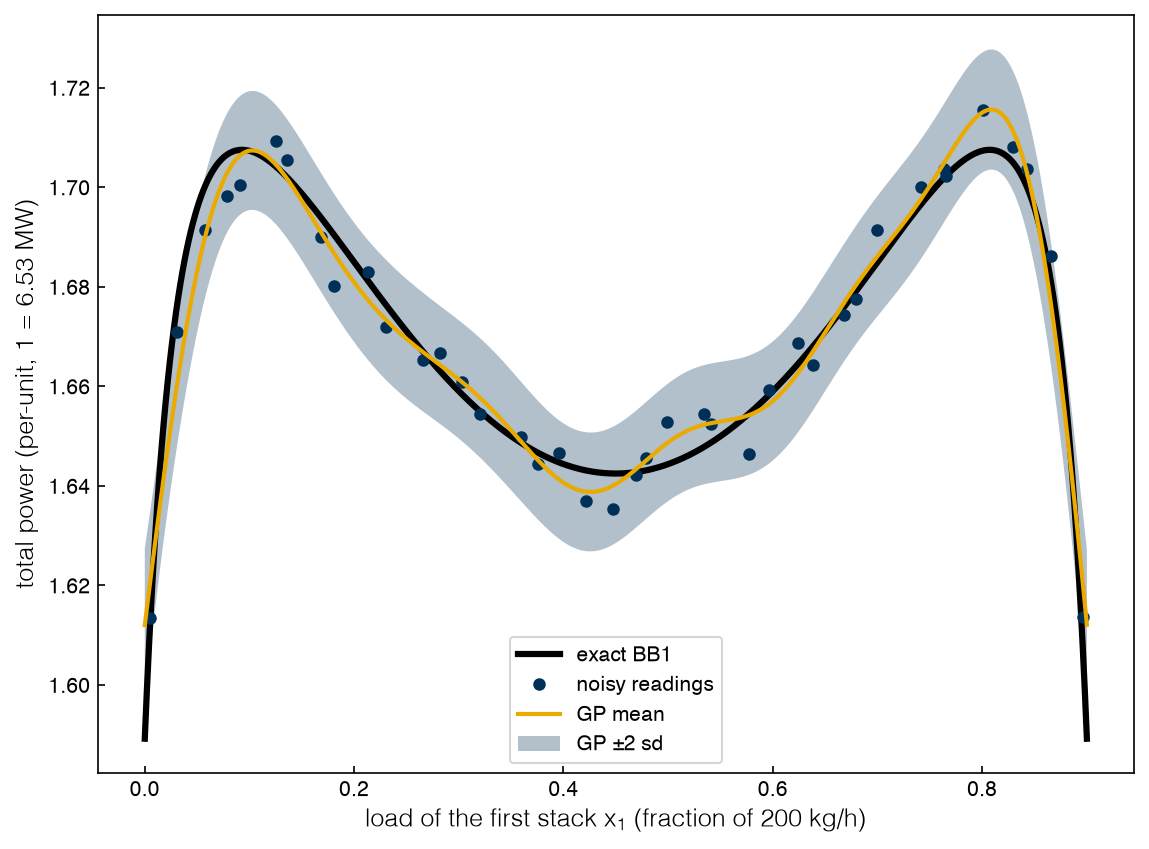

In [4]:
from scipy.stats import qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

f = NoisyBB1(seed=101)
X = qmc.scale(qmc.LatinHypercube(d=1, seed=1).random(40), 0, 0.9)
y = np.array([f(v) for v in X[:, 0]])
kernel = ConstantKernel(1.0) * RBF(0.2, (0.05, 2.0)) + WhiteKernel(1e-2, (1e-6, 1.0))
gp = GaussianProcessRegressor(kernel, normalize_y=True, random_state=0).fit(X, y)
sigma_hat = np.sqrt(gp.kernel_.k2.noise_level) * y.std()
grid = np.linspace(0, 0.9, 901)
mean, std = gp.predict(grid[:, None], return_std=True)
print(f"GP on 40 noisy readings: estimated noise {sigma_hat:.4f} per-unit (true {SIGMA}), "
      f"surrogate minimum at x1 = {grid[np.argmin(mean)]:.3f}, predicted {mean.min():.4f}, "
      f"true BB1 there {el.bb1(grid[np.argmin(mean)]):.4f}")

fig, ax = plt.subplots()
ax.plot(grid, [el.bb1(v) for v in grid], 'k-', lw=3, label='exact BB1')
ax.plot(X[:, 0], y, 'o', ms=5, label='noisy readings')
ax.plot(grid, mean, '-', label='GP mean')
ax.fill_between(grid, mean - 2 * std, mean + 2 * std, alpha=0.3, label='GP $\\pm 2$ sd')
ax.set_xlabel('load of the first stack $x_1$ (fraction of 200 kg/h)')
ax.set_ylabel('total power (per-unit, 1 = 6.53 MW)')
ax.legend(fontsize=10);

The GP estimates the noise at 0.0053 per-unit against the true value of 0.005, while the smoothed mean puts the minimum at an end, $x_1 = 0$, which is the right answer, since one stack carries the whole demand. The minimum value is overestimated, at 1.612 against the true 1.589, because 40 readings with a length scale of about 0.1 are not able to resolve the sharp rise in power just above zero load, where the parasitic term of the S-curve switches on. The surrogate has therefore found where to look, and a few averaged readings at that point would confirm the value.

The lectures close on the robust reading, where the uncertainty band of the GP is treated as an uncertainty set for the true function. Minimizing the upper edge of the band instead of the mean is a robust surrogate problem, which favors points where the model is both low and confident.

:::{exercise}
:label: ex-t52-noise

Minimize the GP's upper band, mean $+ 2\,$sd, instead of its mean, over $x_1 \in [0, 0.9]$. Does the robust surrogate choose the same load? Then double the noise to 0.01 per-unit and repeat both the Nelder–Mead experiment and the GP fit. Which approach degrades more?
:::

## Summary

- Robust optimization asks for solutions that are feasible for every value in an uncertainty set (box, ellipsoid or polyhedron) and optimizes the worst case.
- The semi-infinite robust constraint becomes a finite robust counterpart by taking the worst case analytically. For a box and nonnegative variables, each uncertain coefficient takes its worst value; ellipsoids give cone constraints; budget sets give extra linear constraints via LP duality. The counterpart stays about the size of the nominal model.
- With no feed purchases, the nominal farmer plan is infeasible in a 20%-low year. The robust plan guarantees \$56,800, 52% below the nominal promise, but earns \$117,500 and \$147,000 in mean and good years once sales adapt.
- Most of the conservatism comes from assuming nothing adapts after the uncertainty is revealed. Adjustable robust optimization lets later decisions follow a decision rule.
- Stochastic programming optimizes the average over weighted scenarios; robust optimization protects against the worst case in a set. The choice depends on what is known about the uncertainty and on what a violation costs.
- Measurement noise in a black box ruins small-step finite differences and stalls direct search. Averaging, regression surrogates with a noise term, and robust surrogate objectives are the remedies.

## Additional Reading

- A. Ben-Tal, L. El Ghaoui and A. Nemirovski, *Robust Optimization*, Princeton University Press (2009).
- D. Bertsimas and M. Sim, "The price of robustness," *Operations Research* 52 (2004) 35–53. The budget uncertainty set.
- D. Bertsimas, D. B. Brown and C. Caramanis, "Theory and applications of robust optimization," *SIAM Review* 53 (2011) 464–501.
- G. Hüllen, J. Zhai, S. H. Kim, A. Sinha, M. J. Realff and F. Boukouvala, "Managing uncertainty in data-driven simulation-based optimization," *Computers & Chemical Engineering* 136 (2020) 106519. The air-capture case study of the last lecture.
- A. R. Conn, K. Scheinberg and L. N. Vicente, *Introduction to Derivative-Free Optimization*, SIAM (2009). Noise and the step-size floor in derivative-free methods.
- J. R. Birge and F. Louveaux, *Introduction to Stochastic Programming*, 2nd ed., Springer (2011).